# Gradient Boosting Regressor - Dự đoán giá RAM DDR5 (USD/GB)

Dự án dự đoán giá RAM DDR5 (USD/GB) từ 3 nguồn dữ liệu CSV sử dụng mô hình **Gradient Boosting Regressor**.
Notebook dùng **cùng dữ liệu, cùng đặc trưng, cùng cách chia train/test và cùng thang đo (MAE)** với bài mẫu Random Forest để so sánh công bằng giữa các mô hình trong nhóm.

**Luồng xử lý:**
1. Đọc & gộp 3 file CSV
2. Trích đặc trưng từ tên sản phẩm (Regex)
3. Khám phá dữ liệu (EDA)
4. Train/Test split theo nhóm (tránh data leakage)
5. Pipeline tiền xử lý + Gradient Boosting
6. Tinh chỉnh siêu tham số (RandomizedSearchCV + GroupKFold)
7. Trực quan hóa kết quả, Learning curve, Feature Importance, Partial Dependence
8. So sánh mô hình, lưu mô hình & dự đoán mẫu

**Người thực hiện:** Duy  |  **Hạn nộp:** 31/10/2026

## Cell 1 — Thư viện và cấu hình

In [1]:
import os
import re
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, RandomizedSearchCV, GroupKFold, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Trong Jupyter thì %matplotlib inline cho phép hiện biểu đồ trực tiếp
%matplotlib inline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
try:
    _HERE = Path(__file__).resolve().parent  # chạy bằng file .py
except NameError:
    _HERE = Path.cwd()  # chạy trong notebook / cell tương tác

# Thư mục dataset/ cùng cấp với notebook
DATA_DIR = Path(os.environ.get("DATA_DIR", _HERE / "dataset"))
RESULTS_DIR = _HERE / "results_gbr"          # kết quả của Gradient Boosting
RF_RESULTS_DIR = _HERE / "results"           # kết quả của Random Forest (để so sánh, nếu có)
RESULTS_DIR.mkdir(exist_ok=True)

print("✅ Sẵn sàng! Thư mục dữ liệu:", DATA_DIR)

FILE_A = DATA_DIR / "ram-price-observations.csv"
FILE_B = DATA_DIR / "ram_pricing_intelligence_2026.csv"
FILE_C = DATA_DIR / "costinflation-ddr5-ram-retail-prices-raw-2026-07-13-to-2026-08-10.csv"

# Kiểm tra file tồn tại trước khi đọc
for f in [FILE_A, FILE_B, FILE_C]:
    if not f.exists():
        raise FileNotFoundError(f"Không tìm thấy file: {f}\nHãy đặt các file CSV vào thư mục: {DATA_DIR}")
print("✅ Tất cả file CSV đã sẵn sàng.")

✅ Sẵn sàng! Thư mục dữ liệu: c:\Users\ASUS TUF Gaming 15\Downloads\dataset
✅ Tất cả file CSV đã sẵn sàng.


## Cell 2 — Đọc 3 file CSV

In [2]:
a = pd.read_csv(FILE_A)
b = pd.read_csv(FILE_B)
c = pd.read_csv(FILE_C)

print("A (bán lẻ Newegg/BestBuy):", a.shape)
print("B (eBay, nhiều loại RAM): ", b.shape)
print("C (costinflation DDR5):   ", c.shape)

print("\n--- Mẫu file A ---")
display(a.head(3))

A (bán lẻ Newegg/BestBuy): (414, 9)
B (eBay, nhiều loại RAM):  (2899, 17)
C (costinflation DDR5):    (19705, 16)

--- Mẫu file A ---


,capture_date_utc,product_id,product_label,kit_capacity_gb,title,seller,price_usd,usd_per_gb,verification_status
0,2026-08-12,corsair-dominator-titanium-6000c30,Corsair Dominator Titanium 32GB (2x16GB) DDR5-...,32,CORSAIR Dominator Titanium 32GB (2 x 16GB) DDR...,Newegg.com,649.99,20.312,discovery_only
1,2026-08-12,corsair-dominator-titanium-6000c30,Corsair Dominator Titanium 32GB (2x16GB) DDR5-...,32,CORSAIR Dominator Titanium 32GB (2 x 16GB) DDR...,Newegg.com,649.99,20.312,discovery_only
2,2026-08-12,corsair-vengeance-6000c30,Corsair Vengeance 32GB (2x16GB) DDR5-6000 CL30,32,Corsair CMK32GX5M2B6000C30 VENGEANCE DDR5 32GB...,Central Computers,529.99,16.562,discovery_only


## Cell 3 — Gộp 3 file về schema chung

Cột chung: `source`, `title`, `capacity_gb`, `price`, `usd_per_gb`, `condition`, `speed_hint`

In [3]:
df_a = pd.DataFrame({
    "source": "A_retail",
    "title": a["title"],
    "capacity_gb": a["kit_capacity_gb"],
    "price": a["price_usd"],
    "usd_per_gb": a["usd_per_gb"],
    "condition": "New",
    "speed_hint": np.nan,
})

b5 = b[(b["ram_generation"] == "DDR5") & (b["is_bulk_server"] == 0) & (b["unit_type"] != "Bulk")].copy()
b5 = b5.dropna(subset=["capacity_gb", "price"])
df_b = pd.DataFrame({
    "source": "B_ebay",
    "title": b5["title"],
    "capacity_gb": b5["capacity_gb"],
    "price": b5["price"],
    "usd_per_gb": b5["price"] / b5["capacity_gb"],
    "condition": b5["condition"],
    "speed_hint": b5["bus_speed_mhz"],
})

c = c[(c["quantity_value"] > 0) & c["normalized_price_amount"].notna()]
df_c = pd.DataFrame({
    "source": "C_costinflation",
    "title": c["product_name"],
    "capacity_gb": c["quantity_value"],
    "price": c["price_amount"],
    "usd_per_gb": c["normalized_price_amount"],
    "condition": "New",
    "speed_hint": np.nan,
})

df = pd.concat([df_a, df_b, df_c], ignore_index=True)
print("Sau khi gộp:", df.shape)
print(df["source"].value_counts())
display(df.head())

Sau khi gộp: (21473, 7)
source
C_costinflation    19704
B_ebay              1355
A_retail             414
Name: count, dtype: int64


,source,title,capacity_gb,price,usd_per_gb,condition,speed_hint
0,A_retail,CORSAIR Dominator Titanium 32GB (2 x 16GB) DDR...,32.0,649.99,20.312,New,NaN
1,A_retail,CORSAIR Dominator Titanium 32GB (2 x 16GB) DDR...,32.0,649.99,20.312,New,NaN
2,A_retail,Corsair CMK32GX5M2B6000C30 VENGEANCE DDR5 32GB...,32.0,529.99,16.562,New,NaN
3,A_retail,CORSAIR - Vengeance 32GB (2 x 16GB) 288-Pin PC...,32.0,539.99,16.875,New,NaN
4,A_retail,CORSAIR Vengeance 32GB (2 x 16GB) 288-Pin PC R...,32.0,539.99,16.875,New,NaN


## Cell 4 — Feature Engineering: Trích đặc trưng từ tên sản phẩm

Dùng **Regex** để đọc thông tin từ chuỗi tên sản phẩm:
- `brand` → hãng sản xuất
- `speed_mhz` → tốc độ bus (MHz)
- `cas_latency` → độ trễ CAS (CL)
- `num_sticks` → số thanh RAM trong kit
- `is_sodimm` → có phải RAM laptop?
- `has_rgb` → có đèn RGB?
- `is_ecc_server` → có phải RAM máy chủ?

In [4]:
BRANDS = ["Corsair", "G.Skill", "Kingston", "Crucial", "Micron", "TEAMGROUP", "T-Force", "Patriot",
          "Samsung", "SK hynix", "A-Tech", "Acer", "Biwin", "ADATA", "XPG", "Lexar", "PNY",
          "OLOy", "Mushkin", "Silicon Power", "Netac", "Thermaltake", "Gigabyte", "ASUS", "MSI"]


def find_brand(t):
    t = str(t).lower().replace(" ", "").replace("-", "").replace(".", "")
    for br in BRANDS:
        if br.lower().replace(" ", "").replace("-", "").replace(".", "") in t:
            return br
    if "hynix" in t:
        return "SK hynix"
    if "gskill" in t or "tridentz" in t:
        return "G.Skill"
    return "Other"


def find_speed(row):
    if pd.notna(row["speed_hint"]):
        return row["speed_hint"]
    t = str(row["title"])
    m = re.search(r"\b([3-9]\d{3})\s*(?:MHz|MT/s|MTs)?\b", t, flags=re.I)
    if m:
        return float(m.group(1))
    m = re.search(r"B(\d{4})C\d{2}", t)  # kiểu mã Corsair: ...B6000C30
    return float(m.group(1)) if m else np.nan


def find_cl(t):
    t = str(t)
    m = re.search(r"\bCL\s?-?(\d{2})\b", t, flags=re.I)
    if m:
        return float(m.group(1))
    m = re.search(r"\b(\d{2})-\d{2}-\d{2}-\d{2,3}\b", t)
    if m:
        return float(m.group(1))
    m = re.search(r"B\d{4}C(\d{2})", t)
    return float(m.group(1)) if m else np.nan


def find_sticks(t):
    m = re.search(r"\(?\b(\d)\s*[xX]\s*\d+\s*GB", str(t))
    return int(m.group(1)) if m else 1


df["brand"]        = df["title"].apply(find_brand)
df["speed_mhz"]    = df.apply(find_speed, axis=1)
df["cas_latency"]  = df["title"].apply(find_cl)
df["num_sticks"]   = df["title"].apply(find_sticks)
df["is_sodimm"]    = df["title"].str.contains(r"SO-?DIMM|laptop|notebook", case=False, regex=True).astype(int)
df["has_rgb"]      = df["title"].str.contains("RGB", case=False).astype(int)
df["is_ecc_server"]= df["title"].str.contains(r"ECC|RDIMM|registered|server", case=False, regex=True).astype(int)

# Loại điều kiện hiếm và giá bất thường (outlier)
df = df[~df["condition"].isin(["For parts or not working"])]
q_low, q_high = df["usd_per_gb"].quantile([0.005, 0.995])
df = df[df["usd_per_gb"].between(q_low, q_high)].reset_index(drop=True)

print("✅ Sau khi làm sạch:", df.shape)
display(df[["source", "brand", "capacity_gb", "speed_mhz", "cas_latency", "num_sticks", "usd_per_gb"]].head())

✅ Sau khi làm sạch: (21268, 14)


,source,brand,capacity_gb,speed_mhz,cas_latency,num_sticks,usd_per_gb
0,A_retail,Corsair,32.0,6000.0,30.0,2,20.312
1,A_retail,Corsair,32.0,6000.0,30.0,2,20.312
2,A_retail,Corsair,32.0,6000.0,30.0,2,16.562
3,A_retail,Corsair,32.0,6000.0,30.0,2,16.875
4,A_retail,Corsair,32.0,6000.0,NaN,2,16.875


## Cell 5 — EDA: Khám phá dữ liệu

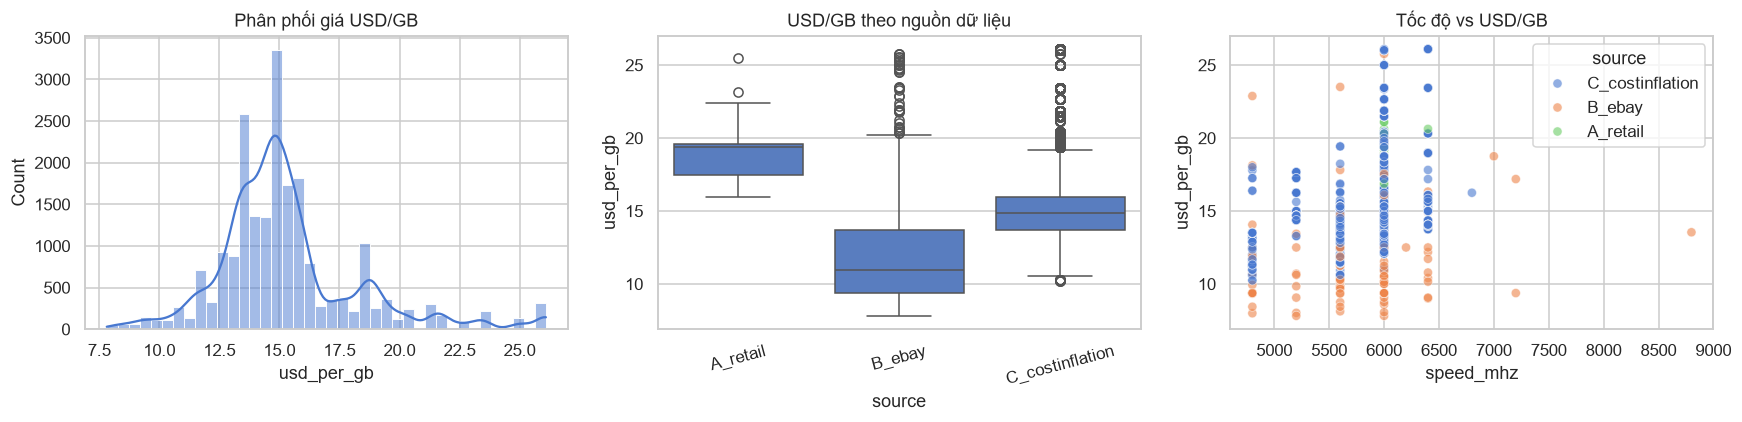


📊 Giá trị bị thiếu:
speed_hint     20163
speed_mhz        106
cas_latency     2156
dtype: int64


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["usd_per_gb"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Phân phối giá USD/GB")

sns.boxplot(data=df, x="source", y="usd_per_gb", ax=axes[1])
axes[1].set_title("USD/GB theo nguồn dữ liệu")
axes[1].tick_params(axis="x", rotation=15)

sns.scatterplot(data=df.sample(min(2000, len(df)), random_state=RANDOM_STATE),
                x="speed_mhz", y="usd_per_gb", hue="source", ax=axes[2], alpha=0.6)
axes[2].set_title("Tốc độ vs USD/GB")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "01_eda.png", dpi=110)
plt.show()

print("\n📊 Giá trị bị thiếu:")
missing = df.isna().sum()
print(missing[missing > 0])

## Cell 5.1 — EDA: Phân phối các đặc trưng số và ma trận tương quan

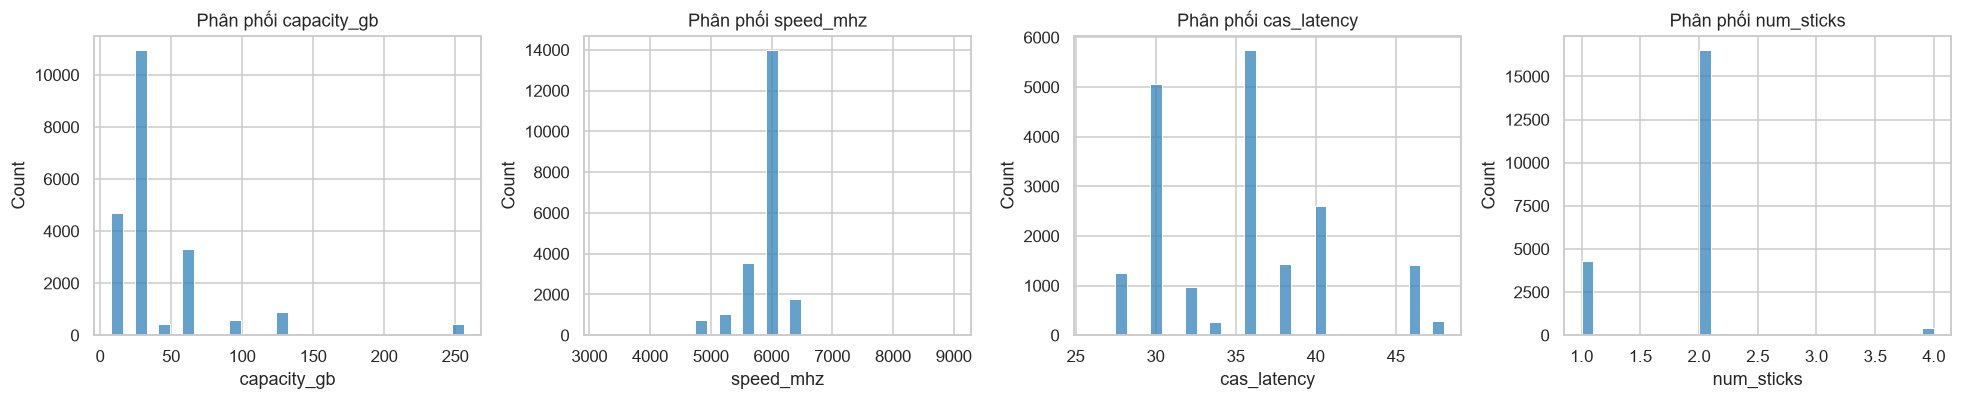

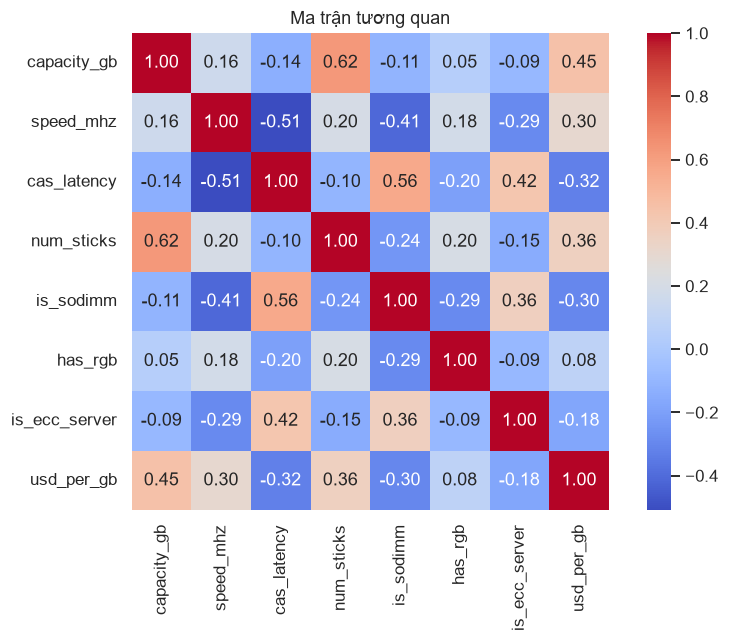

In [6]:
num_eda = ["capacity_gb", "speed_mhz", "cas_latency", "num_sticks"]

# Histogram từng đặc trưng số
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, num_eda):
    sns.histplot(df[c].dropna(), bins=30, kde=False, ax=ax, color="#3182bd")
    ax.set_title(f"Phân phối {c}")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "01b_histogram_dac_trung.png", dpi=110)
plt.show()

# Ma trận tương quan giữa các đặc trưng số và biến mục tiêu
corr_cols = num_eda + ["is_sodimm", "has_rgb", "is_ecc_server", "usd_per_gb"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Ma trận tương quan")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "01c_tuong_quan.png", dpi=110)
plt.show()

## Cell 5.2 — EDA: Giá theo hãng, tình trạng, dung lượng và các đặc trưng nhị phân

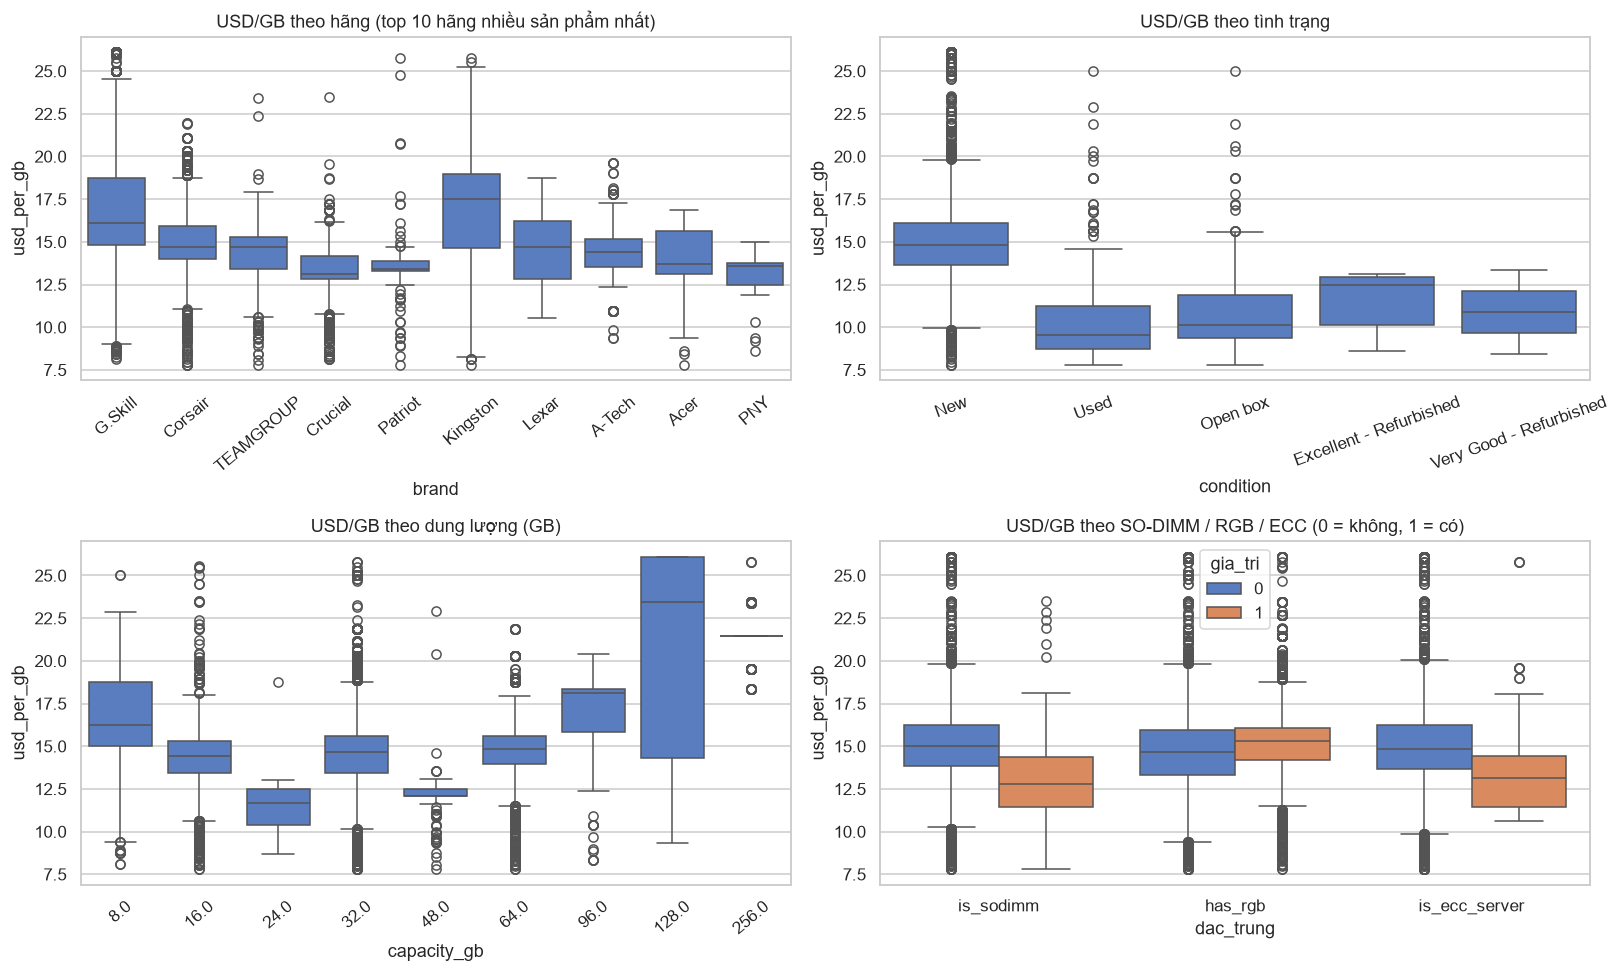

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Top 10 hãng theo số lượng sản phẩm: giá USD/GB
top_brands = df["brand"].value_counts().head(10).index
sns.boxplot(data=df[df["brand"].isin(top_brands)], x="brand", y="usd_per_gb",
            order=top_brands, ax=axes[0, 0])
axes[0, 0].set_title("USD/GB theo hãng (top 10 hãng nhiều sản phẩm nhất)")
axes[0, 0].tick_params(axis="x", rotation=40)

# Tình trạng
sns.boxplot(data=df, x="condition", y="usd_per_gb", ax=axes[0, 1])
axes[0, 1].set_title("USD/GB theo tình trạng")
axes[0, 1].tick_params(axis="x", rotation=20)

# Dung lượng
sns.boxplot(data=df, x="capacity_gb", y="usd_per_gb", ax=axes[1, 0])
axes[1, 0].set_title("USD/GB theo dung lượng (GB)")
axes[1, 0].tick_params(axis="x", rotation=40)

# Đặc trưng nhị phân: SO-DIMM / RGB / ECC
bin_long = df.melt(id_vars="usd_per_gb", value_vars=["is_sodimm", "has_rgb", "is_ecc_server"],
                   var_name="dac_trung", value_name="gia_tri")
sns.boxplot(data=bin_long, x="dac_trung", y="usd_per_gb", hue="gia_tri", ax=axes[1, 1])
axes[1, 1].set_title("USD/GB theo SO-DIMM / RGB / ECC (0 = không, 1 = có)")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "01d_gia_theo_nhom.png", dpi=110)
plt.show()

## Cell 6 — Chia Train / Test (GroupShuffleSplit)

> ⚠️ Dùng **GroupShuffleSplit** để đảm bảo cùng một sản phẩm không xuất hiện ở cả train lẫn test — tránh **data leakage**.

In [8]:
TARGET   = "usd_per_gb"
NUM_COLS = ["capacity_gb", "speed_mhz", "cas_latency", "num_sticks", "is_sodimm", "has_rgb", "is_ecc_server"]
CAT_COLS = ["brand", "source", "condition"]

X = df[NUM_COLS + CAT_COLS]
y = df[TARGET]
groups = df["title"].str.lower().str.replace(r"\s+", " ", regex=True)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test   = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test   = y.iloc[train_idx], y.iloc[test_idx]
groups_train      = groups.iloc[train_idx]

print(f"✅ Train: {len(X_train)} dòng | Test: {len(X_test)} dòng")

✅ Train: 16518 dòng | Test: 4750 dòng


## Cell 7 — Pipeline tiền xử lý + Gradient Boosting cơ bản

Pipeline gồm 2 bước (tiền xử lý **giống hệt** bài mẫu Random Forest):
1. **Tiền xử lý**: điền NaN bằng median, One-Hot Encode cột chữ
2. **Mô hình**: `GradientBoostingRegressor` với 300 cây, `learning_rate=0.1`, `max_depth=3`

> Gradient Boosting xây cây **tuần tự**: mỗi cây mới học phần sai số còn lại của các cây trước, khác với Random Forest xây các cây độc lập rồi lấy trung bình.

In [9]:
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
])

gbr_base = Pipeline([
    ("prep", preprocess),
    ("gbr", GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=3,
                                      random_state=RANDOM_STATE)),
])
gbr_base.fit(X_train, y_train)

results = {}   # lưu MAE / RMSE / R2 của từng mô hình để so sánh ở cuối


def evaluate(model, name):
    pred = model.predict(X_test)
    mae  = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2   = r2_score(y_test, pred)
    results[name] = {"MAE": mae, "RMSE": rmse, "R2": r2}
    print(f"[{name}]  MAE = {mae:.3f} USD/GB | RMSE = {rmse:.3f} | R² = {r2:.3f}")
    return pred


pred_base = evaluate(gbr_base, "GB mặc định")

mean_pred = np.full(len(y_test), y_train.mean())
baseline_mae = mean_absolute_error(y_test, mean_pred)
results["Baseline đoán trung bình"] = {
    "MAE": baseline_mae,
    "RMSE": np.sqrt(mean_squared_error(y_test, mean_pred)),
    "R2": r2_score(y_test, mean_pred),
}
print(f"[Baseline đoán trung bình]  MAE = {baseline_mae:.3f} USD/GB")

# Kiểm tra overfitting: so sánh sai số train và test
train_mae = mean_absolute_error(y_train, gbr_base.predict(X_train))
print(f"\nMAE train = {train_mae:.3f} | MAE test = {results['GB mặc định']['MAE']:.3f}")

[GB mặc định]  MAE = 1.325 USD/GB | RMSE = 2.049 | R² = 0.450
[Baseline đoán trung bình]  MAE = 1.927 USD/GB

MAE train = 0.627 | MAE test = 1.325


## Cell 8 — Tinh chỉnh siêu tham số (RandomizedSearchCV + GroupKFold)

Thử **15 tổ hợp tham số** ngẫu nhiên × **3-fold GroupKFold** = 45 lần fit, chấm điểm theo MAE giống bài mẫu.

Các siêu tham số quan trọng của Gradient Boosting:
- `n_estimators`, `learning_rate`: số cây và tốc độ học (đánh đổi lẫn nhau: learning_rate nhỏ cần nhiều cây hơn)
- `max_depth`, `min_samples_leaf`: độ phức tạp của từng cây
- `subsample`: tỉ lệ mẫu dùng cho mỗi cây (< 1 là *Stochastic Gradient Boosting*, giúp giảm overfitting)
- `loss`: `squared_error` hoặc `huber` (ít nhạy với giá ngoại lai hơn)

> ⏳ Cell này mất khoảng 3–10 phút tùy máy vì Gradient Boosting huấn luyện tuần tự.

In [10]:
param_dist = {
    "gbr__n_estimators":     [200, 300, 500],
    "gbr__learning_rate":    [0.03, 0.05, 0.1],
    "gbr__max_depth":        [3, 4, 5, 6],
    "gbr__min_samples_leaf": [1, 5, 10],
    "gbr__subsample":        [0.7, 0.85, 1.0],
    "gbr__max_features":     [None, "sqrt", 0.5],
    "gbr__loss":             ["squared_error", "huber"],
}

search = RandomizedSearchCV(
    gbr_base, param_dist, n_iter=15, cv=GroupKFold(n_splits=3),
    scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
search.fit(X_train, y_train, groups=groups_train)

print("\n🏆 Tham số tốt nhất:", search.best_params_)
print(f"📉 CV MAE tốt nhất: {-search.best_score_:.3f}")

gbr_best  = search.best_estimator_
pred_best = evaluate(gbr_best, "GB đã tinh chỉnh")

Fitting 3 folds for each of 15 candidates, totalling 45 fits

🏆 Tham số tốt nhất: {'gbr__subsample': 0.85, 'gbr__n_estimators': 500, 'gbr__min_samples_leaf': 10, 'gbr__max_features': 0.5, 'gbr__max_depth': 6, 'gbr__loss': 'huber', 'gbr__learning_rate': 0.05}
📉 CV MAE tốt nhất: 1.084
[GB đã tinh chỉnh]  MAE = 1.154 USD/GB | RMSE = 1.753 | R² = 0.597


In [11]:
# 10 tổ hợp siêu tham số tốt nhất
cvr = pd.DataFrame(search.cv_results_)
cvr["cv_mae"] = -cvr["mean_test_score"]
cols = ["rank_test_score", "cv_mae", "std_test_score"] + [c for c in cvr.columns if c.startswith("param_gbr__")]
display(cvr.sort_values("rank_test_score")[cols].head(10).round(4))

,rank_test_score,cv_mae,std_test_score,param_gbr__subsample,param_gbr__n_estimators,param_gbr__min_samples_leaf,param_gbr__max_features,param_gbr__max_depth,param_gbr__loss,param_gbr__learning_rate
3,1,1.0842,0.0322,0.85,500,10,0.5,6,huber,0.05
6,2,1.1073,0.0543,1.00,300,10,None,4,huber,0.10
10,3,1.1266,0.0033,0.85,500,1,0.5,4,huber,0.03
2,4,1.1287,0.1011,1.00,300,10,sqrt,5,squared_error,0.05
0,5,1.1335,0.0299,0.85,200,10,0.5,4,huber,0.05
13,6,1.1465,0.0481,0.70,500,10,None,5,squared_error,0.10
4,7,1.1485,0.0470,1.00,300,10,0.5,4,huber,0.05
5,8,1.1584,0.1087,0.70,500,5,sqrt,4,huber,0.05
11,9,1.1622,0.0559,1.00,300,10,None,6,huber,0.05
14,10,1.1630,0.0602,0.70,500,1,None,4,squared_error,0.03


## Cell 9 — Trực quan hóa kết quả

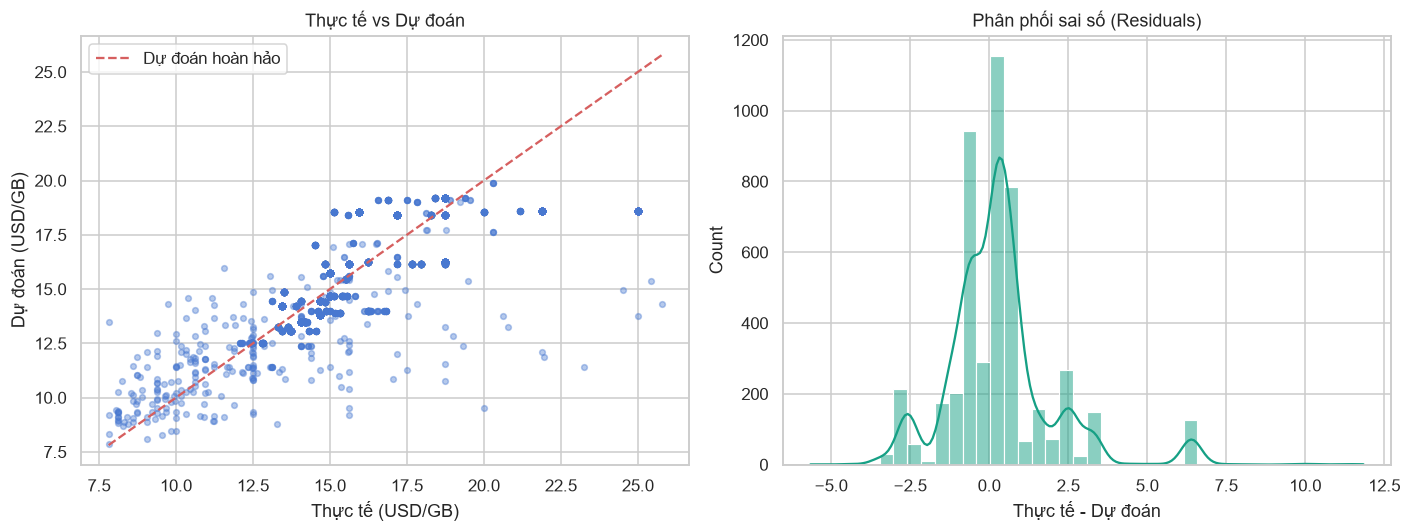

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ Actual vs Predicted
axes[0].scatter(y_test, pred_best, alpha=0.4, s=14)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--", label="Dự đoán hoàn hảo")
axes[0].set_xlabel("Thực tế (USD/GB)")
axes[0].set_ylabel("Dự đoán (USD/GB)")
axes[0].set_title("Thực tế vs Dự đoán")
axes[0].legend()

# Biểu đồ phân phối sai số
residuals = y_test - pred_best
sns.histplot(residuals, bins=40, kde=True, ax=axes[1], color="#16a085")
axes[1].set_title("Phân phối sai số (Residuals)")
axes[1].set_xlabel("Thực tế - Dự đoán")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "02_actual_vs_pred.png", dpi=110)
plt.show()

## Cell 9.1 — Phần dư theo giá trị dự đoán và Q-Q plot

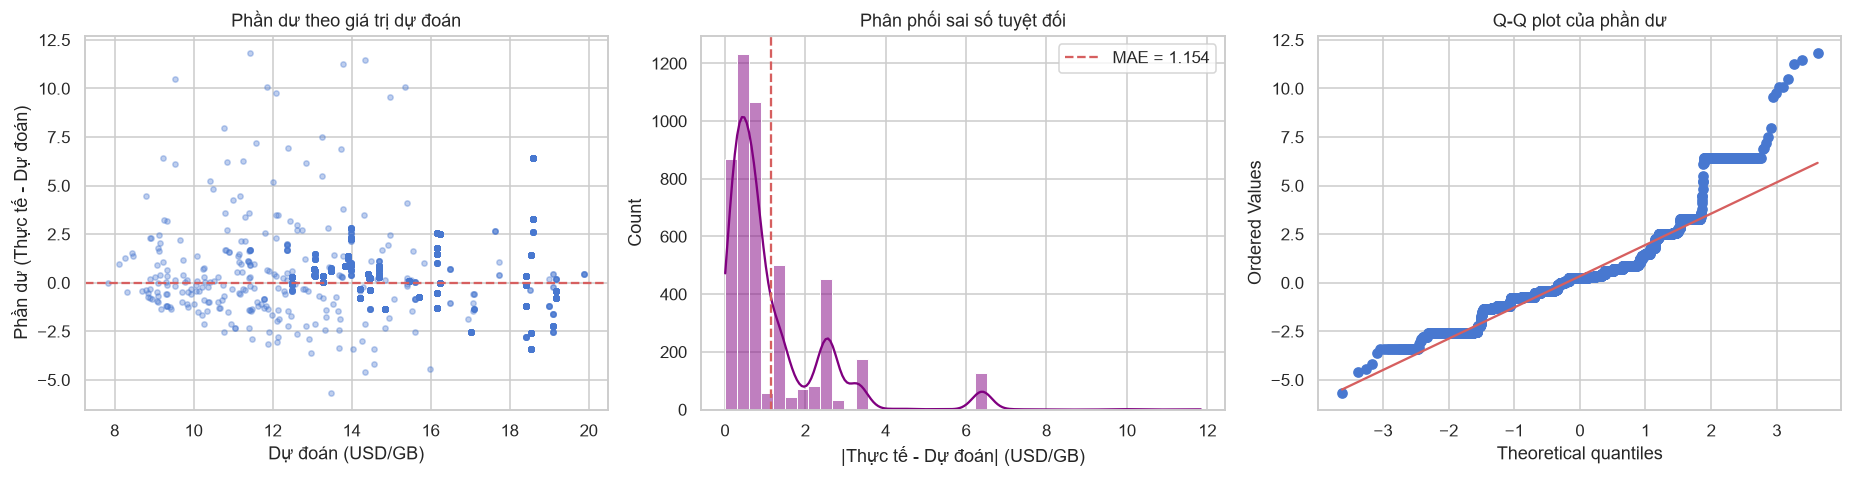

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Phần dư theo giá trị dự đoán
axes[0].scatter(pred_best, residuals, alpha=0.35, s=12)
axes[0].axhline(0, color="r", linestyle="--")
axes[0].set_xlabel("Dự đoán (USD/GB)")
axes[0].set_ylabel("Phần dư (Thực tế - Dự đoán)")
axes[0].set_title("Phần dư theo giá trị dự đoán")

# Phân phối sai số tuyệt đối
abs_err = np.abs(residuals)
sns.histplot(abs_err, bins=40, kde=True, ax=axes[1], color="purple")
axes[1].axvline(abs_err.mean(), color="r", linestyle="--", label=f"MAE = {abs_err.mean():.3f}")
axes[1].set_title("Phân phối sai số tuyệt đối")
axes[1].set_xlabel("|Thực tế - Dự đoán| (USD/GB)")
axes[1].legend()

# Q-Q plot
stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot của phần dư")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "02b_phan_du.png", dpi=110)
plt.show()

## Cell 9.2 — Sai số theo số lượng cây (phát hiện overfitting)

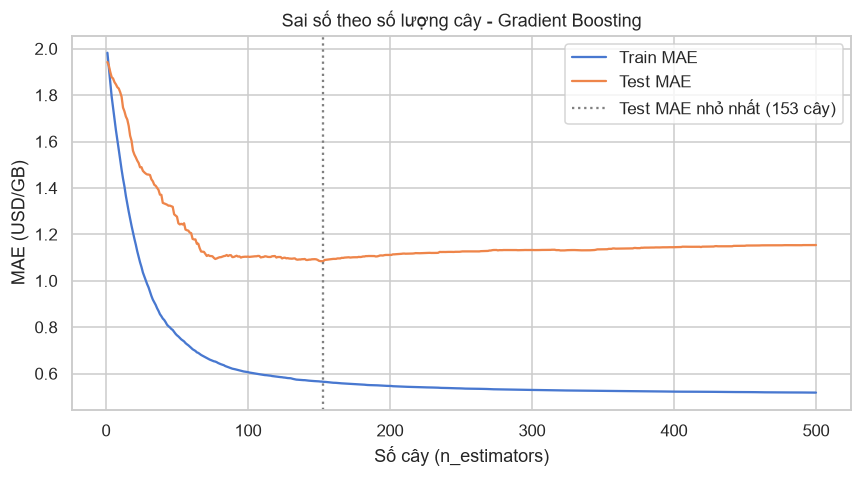

Mô hình dùng 500 cây; Test MAE thấp nhất tại 153 cây.


In [14]:
prep_fit = gbr_best.named_steps["prep"]
gbr_fit  = gbr_best.named_steps["gbr"]
Xtr_t = prep_fit.transform(X_train)
Xte_t = prep_fit.transform(X_test)

train_curve = [mean_absolute_error(y_train, p) for p in gbr_fit.staged_predict(Xtr_t)]
test_curve  = [mean_absolute_error(y_test,  p) for p in gbr_fit.staged_predict(Xte_t)]
best_trees  = int(np.argmin(test_curve)) + 1

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(train_curve) + 1), train_curve, label="Train MAE")
plt.plot(range(1, len(test_curve) + 1),  test_curve,  label="Test MAE")
plt.axvline(best_trees, color="gray", linestyle=":", label=f"Test MAE nhỏ nhất ({best_trees} cây)")
plt.xlabel("Số cây (n_estimators)")
plt.ylabel("MAE (USD/GB)")
plt.title("Sai số theo số lượng cây - Gradient Boosting")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "02c_sai_so_theo_so_cay.png", dpi=110)
plt.show()
print(f"Mô hình dùng {gbr_fit.n_estimators} cây; Test MAE thấp nhất tại {best_trees} cây.")

## Cell 9.3 — Ảnh hưởng của siêu tham số đến CV MAE

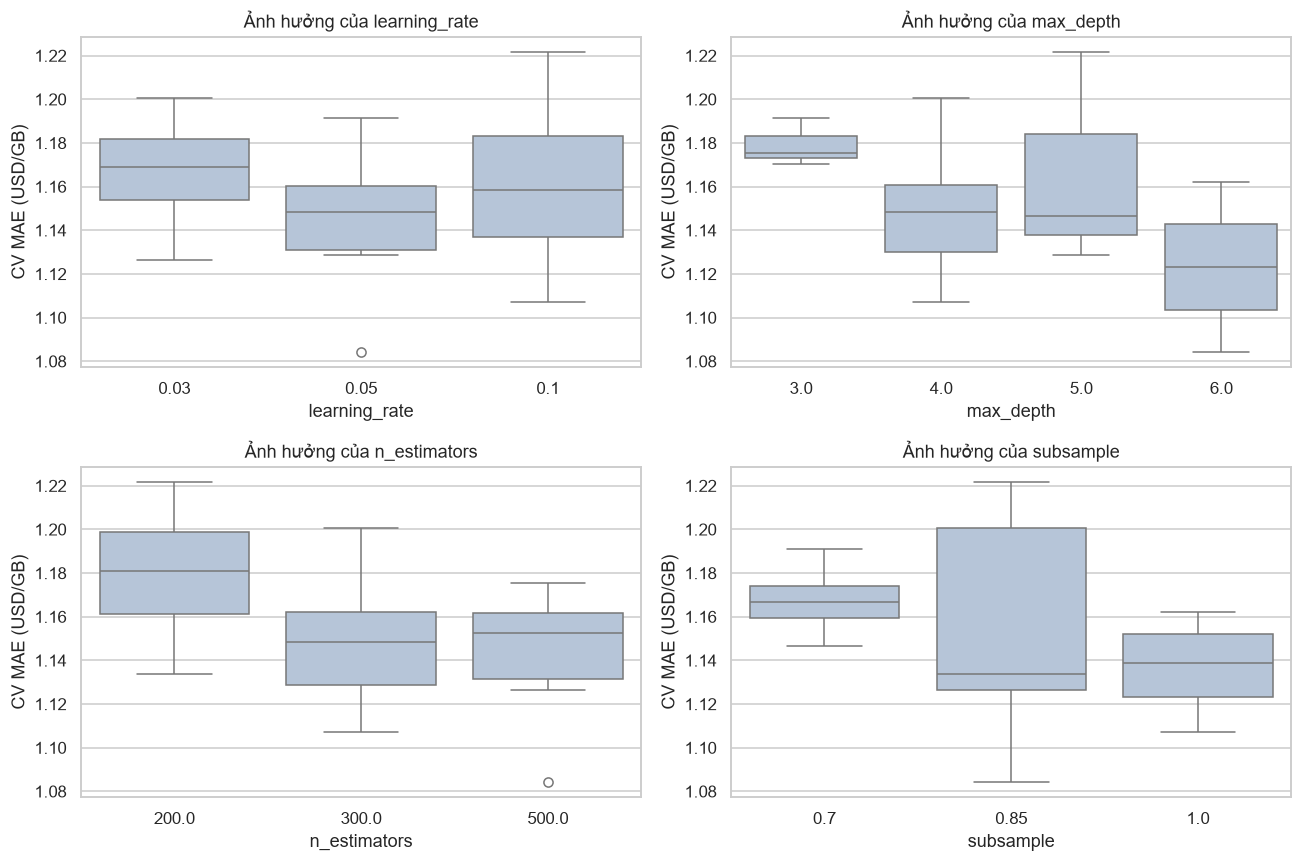

In [15]:
hp = ["learning_rate", "max_depth", "n_estimators", "subsample"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, p in zip(axes.ravel(), hp):
    col = cvr[f"param_gbr__{p}"].astype(float)
    sns.boxplot(x=col, y=cvr["cv_mae"], order=sorted(col.unique()), ax=ax, color="lightsteelblue")
    ax.set_xlabel(p)
    ax.set_ylabel("CV MAE (USD/GB)")
    ax.set_title(f"Ảnh hưởng của {p}")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "02d_anh_huong_sieu_tham_so.png", dpi=110)
plt.show()

## Cell 9.4 — Learning curve (GroupKFold)

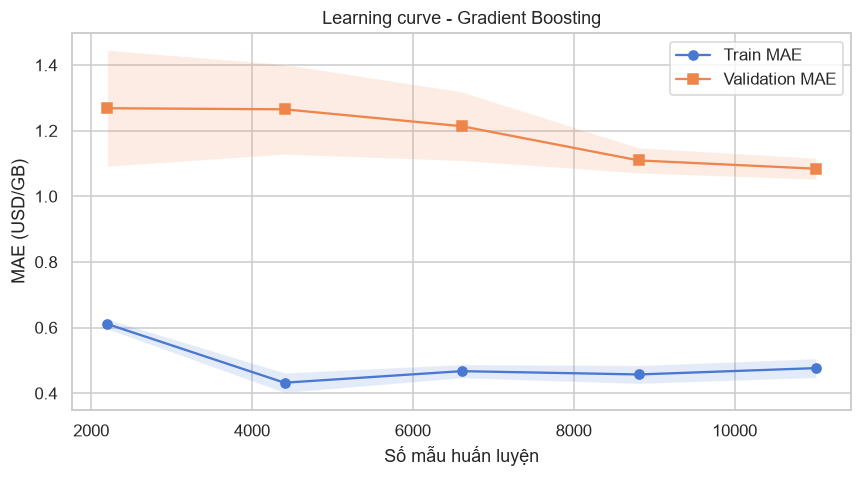

In [16]:
sizes, tr_sc, va_sc = learning_curve(
    gbr_best, X_train, y_train, groups=groups_train, cv=GroupKFold(n_splits=3),
    scoring="neg_mean_absolute_error", train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1,
)
tr_mae, va_mae = -tr_sc, -va_sc

plt.figure(figsize=(8, 4.5))
plt.plot(sizes, tr_mae.mean(axis=1), "o-", label="Train MAE")
plt.plot(sizes, va_mae.mean(axis=1), "s-", label="Validation MAE")
plt.fill_between(sizes, tr_mae.mean(1) - tr_mae.std(1), tr_mae.mean(1) + tr_mae.std(1), alpha=0.15)
plt.fill_between(sizes, va_mae.mean(1) - va_mae.std(1), va_mae.mean(1) + va_mae.std(1), alpha=0.15)
plt.xlabel("Số mẫu huấn luyện")
plt.ylabel("MAE (USD/GB)")
plt.title("Learning curve - Gradient Boosting")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "02e_learning_curve.png", dpi=110)
plt.show()

## Cell 9.5 — Sai số theo nguồn dữ liệu, hãng và dung lượng

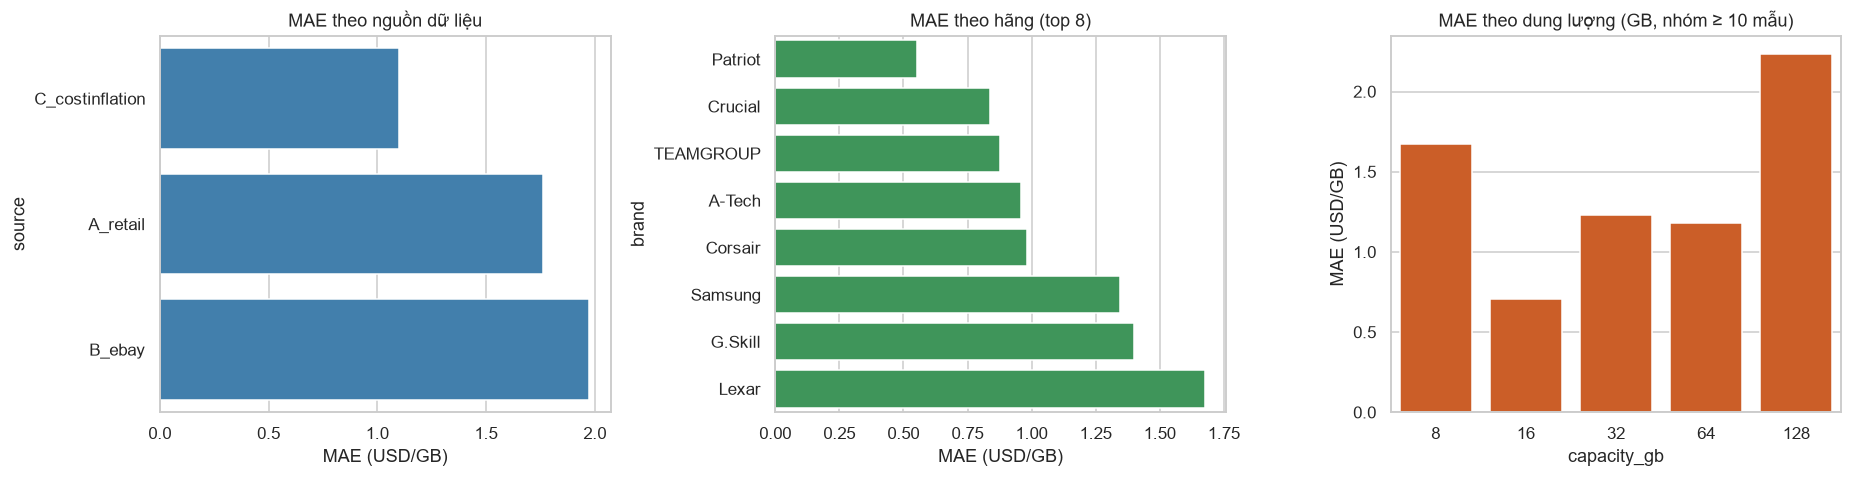

In [17]:
err_df = X_test.copy()
err_df["abs_err"] = np.abs(y_test - pred_best)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

by_src = err_df.groupby("source")["abs_err"].mean().sort_values()
sns.barplot(x=by_src.values, y=by_src.index, ax=axes[0], color="#3182bd")
axes[0].set_title("MAE theo nguồn dữ liệu")
axes[0].set_xlabel("MAE (USD/GB)")

top_b = err_df["brand"].value_counts().head(8).index
by_brand = err_df[err_df["brand"].isin(top_b)].groupby("brand")["abs_err"].mean().sort_values()
sns.barplot(x=by_brand.values, y=by_brand.index, ax=axes[1], color="#31a354")
axes[1].set_title("MAE theo hãng (top 8)")
axes[1].set_xlabel("MAE (USD/GB)")

by_cap = err_df.groupby("capacity_gb")["abs_err"].mean()
by_cap = by_cap[err_df["capacity_gb"].value_counts().reindex(by_cap.index) >= 10]
sns.barplot(x=by_cap.index.astype(int), y=by_cap.values, ax=axes[2], color="#e6550d")
axes[2].set_title("MAE theo dung lượng (GB, nhóm ≥ 10 mẫu)")
axes[2].set_xlabel("capacity_gb")
axes[2].set_ylabel("MAE (USD/GB)")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "02f_sai_so_theo_nhom.png", dpi=110)
plt.show()

## Cell 10 — Feature Importance & Permutation Importance

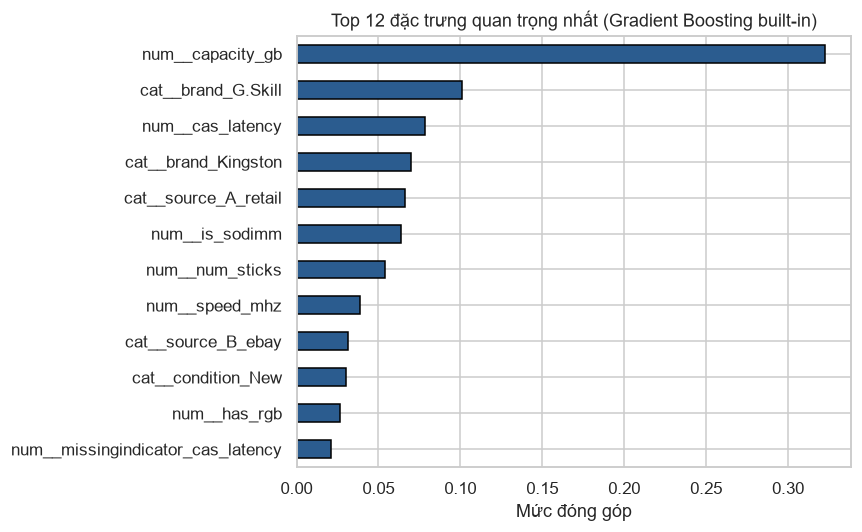

In [18]:
# Feature Importance built-in
feat_names = gbr_best.named_steps["prep"].get_feature_names_out()
imp = pd.Series(gbr_best.named_steps["gbr"].feature_importances_, index=feat_names)
imp.sort_values().tail(12).plot(kind="barh", figsize=(8, 5), color="#2b5c8f", edgecolor="black")
plt.title("Top 12 đặc trưng quan trọng nhất (Gradient Boosting built-in)")
plt.xlabel("Mức đóng góp")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "03_feature_importance.png", dpi=110)
plt.show()

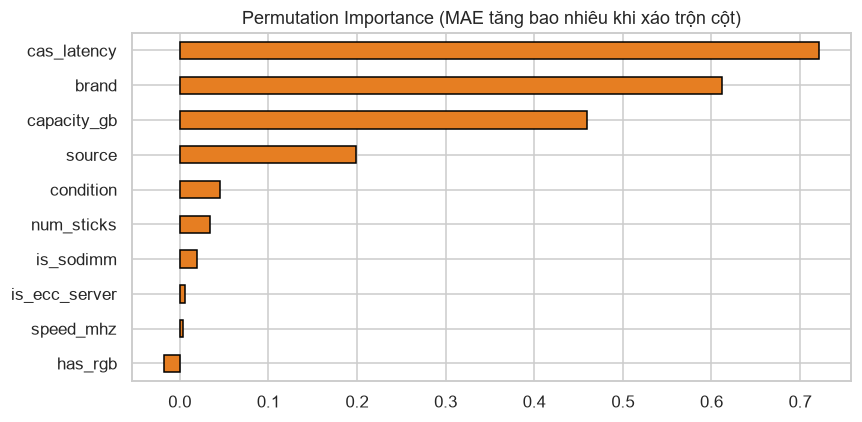

In [19]:
# Permutation Importance (đáng tin cậy hơn — đo trực tiếp trên tập test)
perm = permutation_importance(
    gbr_best, X_test, y_test,
    n_repeats=10, random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error"
)
perm_s = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
perm_s.plot(kind="barh", figsize=(8, 4), color="#e67e22", edgecolor="black")
plt.title("Permutation Importance (MAE tăng bao nhiêu khi xáo trộn cột)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "04_permutation_importance.png", dpi=110)
plt.show()

## Cell 10.1 — Partial Dependence: ảnh hưởng của đặc trưng số đến giá dự đoán

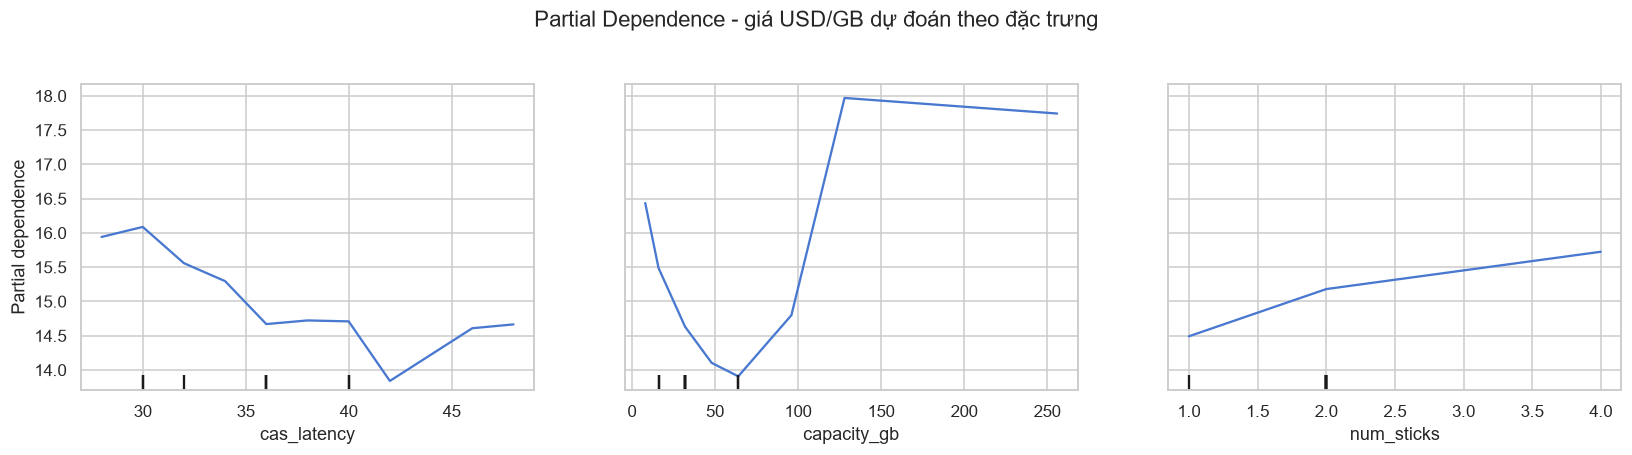

In [20]:
num_for_pdp = ["capacity_gb", "speed_mhz", "cas_latency", "num_sticks"]
top_pdp = [c for c in perm_s.sort_values(ascending=False).index if c in num_for_pdp][:3]

# Đổi cột số sang float để tránh lỗi "integer data"
pdp_sample = X_train.sample(min(2000, len(X_train)), random_state=RANDOM_STATE).copy()
pdp_sample[NUM_COLS] = pdp_sample[NUM_COLS].astype(float)

disp = PartialDependenceDisplay.from_estimator(gbr_best, pdp_sample, top_pdp, kind="average")
disp.figure_.set_size_inches(5 * len(top_pdp), 4)
disp.figure_.suptitle("Partial Dependence - giá USD/GB dự đoán theo đặc trưng", y=1.03)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "05_partial_dependence.png", dpi=110, bbox_inches="tight")
plt.show()

## Cell 11 — So sánh các mô hình

Bảng và biểu đồ so sánh gồm: baseline đoán trung bình, Gradient Boosting mặc định, Gradient Boosting đã tinh chỉnh.
Nếu thư mục `results/` chứa file `rf_ram_price.joblib` (do bài Random Forest tạo ra) thì **tự động thêm Random Forest** vào bảng so sánh.

ℹ️ Không thấy c:\Users\ASUS TUF Gaming 15\Downloads\results\rf_ram_price.joblib → chỉ so sánh các mô hình Gradient Boosting.


,MAE,RMSE,R2
GB đã tinh chỉnh,1.154,1.753,0.597
GB mặc định,1.325,2.049,0.450
Baseline đoán trung bình,1.927,2.866,-0.077


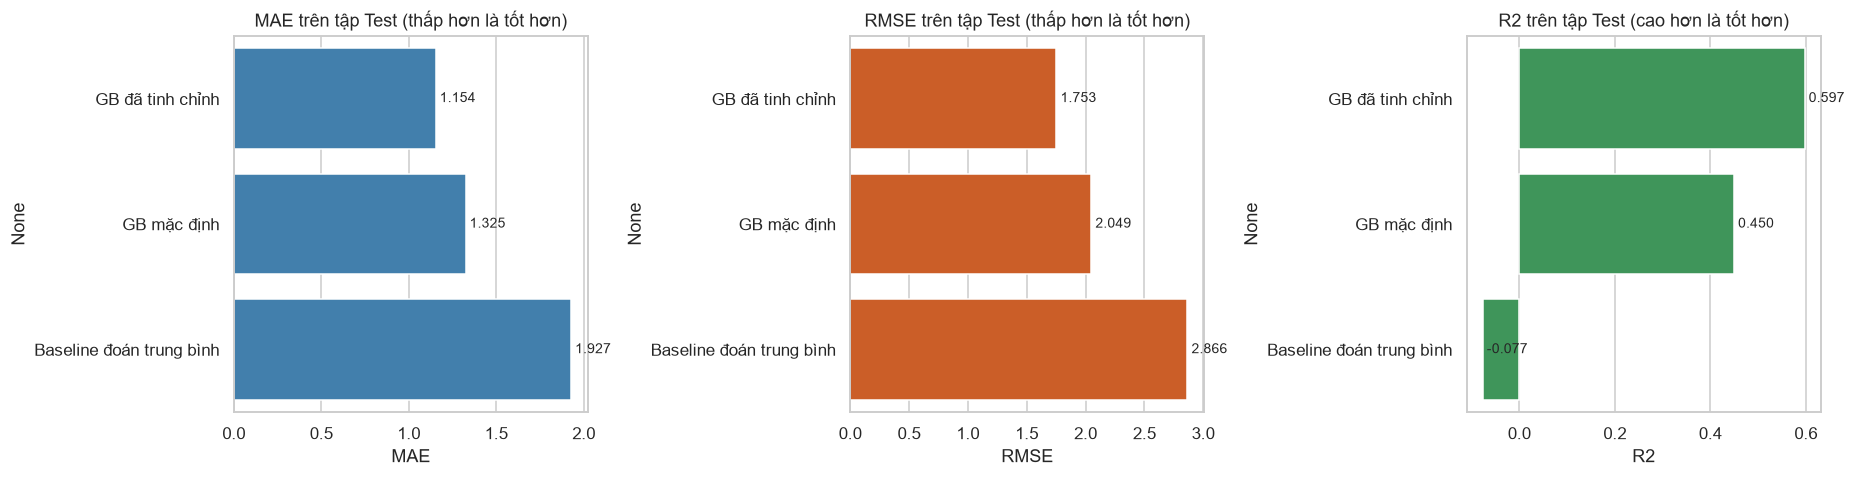

In [21]:
rf_path = RF_RESULTS_DIR / "rf_ram_price.joblib"
if rf_path.exists():
    try:
        rf_model = joblib.load(rf_path)
        evaluate(rf_model, "Random Forest (từ results/)")
    except Exception as e:
        print("⚠️ Không tải được mô hình Random Forest:", e)
else:
    print(f"ℹ️ Không thấy {rf_path} → chỉ so sánh các mô hình Gradient Boosting.")

compare = pd.DataFrame(results).T.sort_values("MAE")
display(compare.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric, color in zip(axes, ["MAE", "RMSE", "R2"], ["#3182bd", "#e6550d", "#31a354"]):
    s = compare[metric].sort_values(ascending=(metric != "R2"))
    sns.barplot(x=s.values, y=s.index, ax=ax, color=color)
    for i, v in enumerate(s.values):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)
    ax.set_title(f"{metric} trên tập Test" + (" (thấp hơn là tốt hơn)" if metric != "R2" else " (cao hơn là tốt hơn)"))
    ax.set_xlabel(metric)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "06_so_sanh_mo_hinh.png", dpi=110)
plt.show()

compare.round(4).to_csv(RESULTS_DIR / "ket_qua_gbr.csv", encoding="utf-8-sig")

## Cell 12 — Lưu mô hình & Dự đoán mẫu

In [22]:
# Lưu mô hình
model_path = RESULTS_DIR / "gbr_ram_price.joblib"
joblib.dump(gbr_best, model_path)
print(f"💾 Mô hình đã lưu: {model_path}")

# Dự đoán một sản phẩm mẫu
sample = pd.DataFrame([{
    "capacity_gb": 32, "speed_mhz": 6000, "cas_latency": 30, "num_sticks": 2,
    "is_sodimm": 0, "has_rgb": 1, "is_ecc_server": 0,
    "brand": "Corsair", "source": "A_retail", "condition": "New",
}])
pred_sample = gbr_best.predict(sample)[0]
print(f"\n🎯 Dự đoán: {pred_sample:.2f} USD/GB")
print(f"   → Kit 32GB ≈ {pred_sample * 32:.0f} USD")

💾 Mô hình đã lưu: c:\Users\ASUS TUF Gaming 15\Downloads\results_gbr\gbr_ram_price.joblib

🎯 Dự đoán: 19.60 USD/GB
   → Kit 32GB ≈ 627 USD


## Cell 13 — Tải lại mô hình và dự đoán tùy chỉnh

Thay đổi các giá trị trong `my_ram` để dự đoán RAM bất kỳ:

In [23]:
# Tải lại mô hình đã lưu (có thể dùng ở file khác)
model = joblib.load(RESULTS_DIR / "gbr_ram_price.joblib")

# ✏️ Thay đổi thông số RAM muốn dự đoán tại đây:
my_ram = pd.DataFrame([{
    "capacity_gb":  64,          # Dung lượng tổng (GB)
    "speed_mhz":    5600,        # Tốc độ bus (MHz)
    "cas_latency":  36,          # CAS Latency
    "num_sticks":   2,           # Số thanh
    "is_sodimm":    0,           # 1 nếu là RAM laptop
    "has_rgb":      0,           # 1 nếu có đèn RGB
    "is_ecc_server": 0,         # 1 nếu là RAM máy chủ ECC
    "brand":        "G.Skill",  # Hãng sản xuất
    "source":       "A_retail", # Nguồn dữ liệu
    "condition":    "New",      # Tình trạng
}])

result = model.predict(my_ram)[0]
cap    = my_ram["capacity_gb"].iloc[0]
print(f"🎯 Dự đoán: {result:.2f} USD/GB")
print(f"   → Kit {cap:.0f}GB ≈ {result * cap:.0f} USD")

🎯 Dự đoán: 18.07 USD/GB
   → Kit 64GB ≈ 1157 USD


## Cell 14 — Nhận xét tự động (tham khảo khi viết báo cáo)

In [24]:
best = results["GB đã tinh chỉnh"]
default = results["GB mặc định"]
gain_vs_mean = (1 - best["MAE"] / results["Baseline đoán trung bình"]["MAE"]) * 100
gain_vs_default = (1 - best["MAE"] / default["MAE"]) * 100

print("NHẬN XÉT:")
print(f"- Gradient Boosting đã tinh chỉnh đạt MAE = {best['MAE']:.3f} USD/GB, RMSE = {best['RMSE']:.3f}, R² = {best['R2']:.3f}.")
print(f"- So với baseline đoán trung bình, MAE giảm {gain_vs_mean:.1f}%.")
print(f"- So với Gradient Boosting mặc định, tinh chỉnh siêu tham số làm MAE thay đổi {gain_vs_default:+.1f}%.")
print(f"- Đặc trưng quan trọng nhất (permutation): {perm_s.sort_values(ascending=False).index[0]}.")
if best["RMSE"] > 1.5 * best["MAE"]:
    print("- RMSE lớn hơn MAE đáng kể → còn một số mẫu bị dự đoán sai nhiều (giá ngoại lai).")
others = [k for k in results if k.startswith("Random Forest")]
if others:
    rf_mae = results[others[0]]["MAE"]
    kq = "tốt hơn" if best["MAE"] < rf_mae else "kém hơn"
    print(f"- So với Random Forest (MAE = {rf_mae:.3f}), Gradient Boosting {kq} về MAE.")

NHẬN XÉT:
- Gradient Boosting đã tinh chỉnh đạt MAE = 1.154 USD/GB, RMSE = 1.753, R² = 0.597.
- So với baseline đoán trung bình, MAE giảm 40.1%.
- So với Gradient Boosting mặc định, tinh chỉnh siêu tham số làm MAE thay đổi +12.9%.
- Đặc trưng quan trọng nhất (permutation): cas_latency.
- RMSE lớn hơn MAE đáng kể → còn một số mẫu bị dự đoán sai nhiều (giá ngoại lai).
